# 5장. 분석을 믿을 수 있게 만드는 데이터 전처리

이 노트북은 `book/chapters/ch05_data_preprocessing.md` 강의안을 초보자가 그대로 따라 하며 이해할 수 있도록 구성한 실습 자료입니다.

이번 장의 핵심은 데이터를 무조건 깨끗하게 만드는 것이 아니라, 분석 결과를 신뢰할 수 있도록 데이터의 상태를 확인하고 처리 기준을 남기는 것입니다.


## 0. 제출 정보
- 이름:진민승
- GitHub ID:Jinminseung
- 작성일:2026.10.13
- 최종 제출 URL:https://github.com/Jinminseung/llm-data-analysis-study/blob/main/chapter05.ipynb

## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 원본 데이터는 `data/raw/`에 그대로 둡니다.
- 전처리 결과는 `data/processed/`에 별도로 저장합니다.
- 전처리 요약 보고서는 `reports/ch05_preprocessing_summary.md`에 저장합니다.
- 코드가 실행되었다고 끝이 아니라, 처리 기준을 설명할 수 있어야 합니다.


## 1. 왜 전처리가 필요한가

현실의 데이터는 처음부터 분석하기 좋은 형태로 주어지지 않습니다.

예를 들어 다음과 같은 문제가 있을 수 있습니다.

| 문제 유형 | 예시 | 확인할 질문 |
|---|---|---|
| 결측치 | 나이가 비어 있는 고객 | 비어 있는 이유가 무엇인가? 삭제해도 되는가? |
| 중복 | 같은 고객 ID가 여러 번 등장 | 자연스러운 중복인가, 데이터 오류인가? |
| 타입 오류 | 가격이 문자열로 저장됨 | 계산 가능한 숫자형으로 바꿀 수 있는가? |
| 날짜 오류 | 주문일이 문자열로 저장됨 | 월별·요일별 분석에 사용할 수 있는가? |
| 문자열 표기 차이 | `Seoul`, ` Seoul`, `SEOUL` | 같은 값을 하나의 표기로 통일해야 하는가? |
| 이상값 | 수량이 음수이거나 가격이 0원 | 실제 의미가 있는 값인가, 입력 오류인가? |
| 파생 컬럼 필요 | 수량과 단가만 있고 주문금액이 없음 | 분석에 필요한 새 컬럼을 만들 수 있는가? |


## 2. 원본 데이터와 전처리 데이터 분리하기

전처리에서 가장 중요한 원칙은 원본 데이터를 직접 덮어쓰지 않는 것입니다.

```text
data/
├─ raw/
│  ├─ customers.csv
│  ├─ products.csv
│  ├─ orders.csv
│  └─ order_items.csv
└─ processed/
   ├─ customers_clean.csv
   ├─ products_clean.csv
   ├─ orders_clean.csv
   └─ order_items_clean.csv
```

원본과 전처리 결과를 분리하면 실수했을 때 원본으로 돌아갈 수 있고, 전처리 전후 차이를 비교할 수 있습니다.


## 3. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [53]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == 'chapter5':
    PROJECT_ROOT = CURRENT_DIR.parent.parent
else:
    PROJECT_ROOT = CURRENT_DIR

RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('현재 실행 위치:', CURRENT_DIR)
print('프로젝트 루트:', PROJECT_ROOT)
print('원본 데이터 폴더:', RAW_DIR)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('보고서 폴더:', REPORT_DIR)


현재 실행 위치: c:\Users\rhrnf\llm-data-analysis-study\chapter\chapter5
프로젝트 루트: c:\Users\rhrnf\llm-data-analysis-study
원본 데이터 폴더: c:\Users\rhrnf\llm-data-analysis-study\data\raw
전처리 데이터 폴더: c:\Users\rhrnf\llm-data-analysis-study\data\processed
보고서 폴더: c:\Users\rhrnf\llm-data-analysis-study\reports


## 4. 원본 데이터 불러오기

이번 장에서는 온라인 쇼핑몰 예제 데이터 4개를 사용합니다.

- `customers.csv`: 고객 정보
- `products.csv`: 상품 정보
- `orders.csv`: 주문 정보
- `order_items.csv`: 주문 상세 정보


In [54]:
customers = pd.read_csv(RAW_DIR / 'customers.csv')
products = pd.read_csv(RAW_DIR / 'products.csv')
orders = pd.read_csv(RAW_DIR / 'orders.csv')
order_items = pd.read_csv(RAW_DIR / 'order_items.csv')

print('원본 데이터 불러오기 완료')


원본 데이터 불러오기 완료


## 5. 전처리 전 데이터 크기 기록하기

전처리 전 데이터 크기를 기록해 두면 나중에 어떤 데이터가 얼마나 바뀌었는지 비교할 수 있습니다.


In [55]:
raw_data = {
    'customers': customers,
    'products': products,
    'orders': orders,
    'order_items': order_items,
}

raw_shapes = pd.DataFrame({
    'dataset': list(raw_data.keys()),
    'rows': [df.shape[0] for df in raw_data.values()],
    'columns': [df.shape[1] for df in raw_data.values()],
})

raw_shapes


,dataset,rows,columns
0,customers,150,6
1,products,100,4
2,orders,300,5
3,order_items,764,5


In [56]:
for name, df in raw_data.items():
    print(f'[{name}]')
    print('shape:', df.shape)
    print('columns:', list(df.columns))
    print()


[customers]
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']

[products]
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']

[orders]
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']

[order_items]
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']



## 6. 원본을 복사해서 전처리 시작하기

전처리 과정에서는 원본 DataFrame을 직접 수정하지 않고 복사본을 사용합니다.


In [57]:
customers_clean = customers.copy()
products_clean = products.copy()
orders_clean = orders.copy()
order_items_clean = order_items.copy()

clean_data = {
    'customers': customers_clean,
    'products': products_clean,
    'orders': orders_clean,
    'order_items': order_items_clean,
}

print('전처리용 복사본 생성 완료')


전처리용 복사본 생성 완료


## 7. 결측치 확인하기

결측치를 처리하기 전에 먼저 어디에 얼마나 비어 있는 값이 있는지 확인합니다. 개수와 비율을 함께 보면 데이터 크기에 따른 차이를 이해하기 쉽습니다.


In [58]:
for name, df in clean_data.items():
    print(f'\n[{name}] 결측치 개수')
    print(df.isna().sum())



[customers] 결측치 개수
customer_id    0
name           0
gender         0
age            0
city           0
signup_date    0
dtype: int64

[products] 결측치 개수
product_id      0
product_name    0
category        0
price           0
dtype: int64

[orders] 결측치 개수
order_id          0
customer_id       0
order_date        0
payment_method    0
order_status      0
dtype: int64

[order_items] 결측치 개수
order_item_id    0
order_id         0
product_id       0
quantity         0
unit_price       0
dtype: int64


In [59]:
def missing_summary(df):
    summary = pd.DataFrame({
        'missing_count': df.isna().sum(),
        'missing_ratio': (df.isna().mean() * 100).round(2),
    })
    return summary.sort_values('missing_count', ascending=False)

missing_summary(customers_clean)


,missing_count,missing_ratio
customer_id,0,0.0
name,0,0.0
gender,0,0.0
age,0,0.0
city,0,0.0
signup_date,0,0.0


## 8. 결측치 처리하기

결측치 처리는 컬럼의 의미에 따라 달라집니다.

- 나이처럼 숫자형 컬럼은 중앙값으로 대체할 수 있습니다.
- 도시처럼 범주형 컬럼은 `Unknown`으로 남겨 분석에서 구분할 수 있습니다.

실제 업무에서는 결측치가 왜 생겼는지 먼저 확인해야 합니다.


In [60]:
if 'age' in customers_clean.columns:
    customers_clean['age'] = pd.to_numeric(customers_clean['age'], errors='coerce')
    age_median = customers_clean['age'].median()
    customers_clean['age'] = customers_clean['age'].fillna(age_median)
    print('age 중앙값:', age_median)

if 'city' in customers_clean.columns:
    customers_clean['city'] = customers_clean['city'].fillna('Unknown')

missing_summary(customers_clean)


age 중앙값: 40.0


,missing_count,missing_ratio
customer_id,0,0.0
name,0,0.0
gender,0,0.0
age,0,0.0
city,0,0.0
signup_date,0,0.0


## 9. 중복 확인하기

중복은 맥락에 따라 의미가 다릅니다. `customers`의 `customer_id` 중복은 오류일 가능성이 크지만, `order_items`의 `order_id` 반복은 한 주문에 여러 상품이 들어갈 수 있으므로 자연스럽습니다.


In [61]:
for name, df in clean_data.items():
    print(name, '전체 행 중복 수:', df.duplicated().sum())


customers 전체 행 중복 수: 0
products 전체 행 중복 수: 0
orders 전체 행 중복 수: 0
order_items 전체 행 중복 수: 0


In [62]:
key_checks = {
    'customers': ('customer_id', customers_clean),
    'products': ('product_id', products_clean),
    'orders': ('order_id', orders_clean),
    'order_items': ('order_item_id', order_items_clean),
}

for name, (key_col, df) in key_checks.items():
    if key_col in df.columns:
        print(name, key_col, '중복 수:', df[key_col].duplicated().sum())
    else:
        print(name, key_col, '컬럼 없음')


customers customer_id 중복 수: 0
products product_id 중복 수: 0
orders order_id 중복 수: 0
order_items order_item_id 중복 수: 0


In [63]:
customers_clean = customers_clean.drop_duplicates()
products_clean = products_clean.drop_duplicates()
orders_clean = orders_clean.drop_duplicates()
order_items_clean = order_items_clean.drop_duplicates()

print('완전 중복 행 제거 완료')


완전 중복 행 제거 완료


## 1. 전처리 전 상태 기록
- 각 데이터 shape: 
[customers] shape: (150, 6)
[products] shape: (100, 4)
[orders] shape: (300, 5)
[order_items] shape: (764, 5)
- 결측치: 모든 데이터프레임의 모든 행에서 결측이 존재하지 않는다.
- 전체 중복: 전체 데이터가 모두 중복된 행은 존재하지 않는다.
- 주요 ID 중복: 각 테이블의 PK는 모두 중복이 없다.
- 타입 문제 후보: order_date와 signup_date 모두 문자열 데이터로 보인다.

![전처리 전 상태](images/step01_before.png)
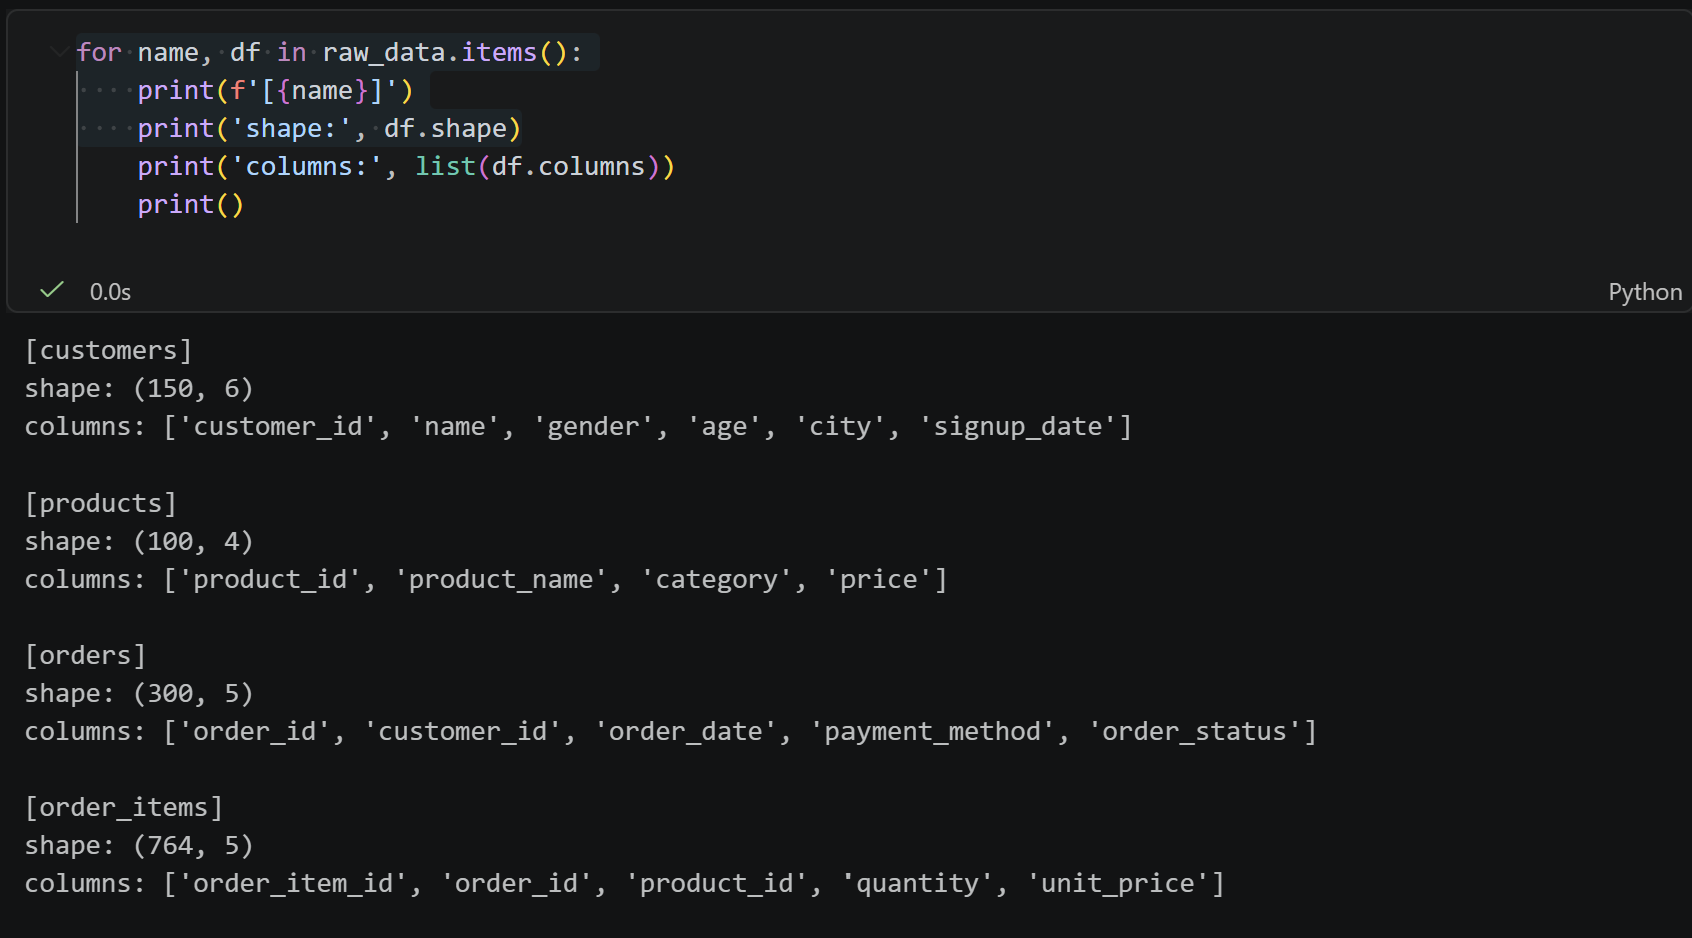
### 결과 관찰
전처리 이전에 결측 및 중복과 관련된 별다른 문제는 관찰되지 않는 것으로 보인다. 다만 날짜 데이터가 문자열로 저장되어 있다.
### 나의 해석과 판단
다만 날짜 데이터가 문자열로 저장되어 있으므로 데이터 타입을 날짜 데이터로 변환해주어야 한다.
### 업무·분석적 의미
기존 데이터에도 결측 및 중복 관련된 별다른 문제가 없는 것으로 보이나, 문자열 공백 등이 남아있어 결측으로 표시되지 않거나 중복으로 표시되지 않는 문제가 있을 수 있어 추가 확인이 필요해보인다. 
### 한계와 추가 확인 사항
중복, 결측 외의 추가적인 데이터 문제(ex)동일한 의미의 데이터가 다른 형태로 저장)가 있는지 확인해볼 필요가 있다.

In [64]:
print(orders['order_date'].dtype)
print(customers['signup_date'].dtype)

str
str


## 10. 문자열 표기 정리하기

문자열 데이터에는 앞뒤 공백이 숨어 있을 수 있습니다. `Seoul`과 ` Seoul `은 눈으로는 비슷하지만 pandas에서는 서로 다른 값입니다.

결측치를 문자열 `nan`으로 바꾸지 않도록 주의하면서 문자열 컬럼의 앞뒤 공백을 제거합니다.


In [65]:
def strip_string_columns(df):
    result = df.copy()
    string_columns = result.select_dtypes(include='object').columns

    for col in string_columns:
        result[col] = result[col].where(
            result[col].isna(),
            result[col].astype(str).str.strip()
        )

    return result

customers_clean = strip_string_columns(customers_clean)
products_clean = strip_string_columns(products_clean)
orders_clean = strip_string_columns(orders_clean)
order_items_clean = strip_string_columns(order_items_clean)

print('문자열 앞뒤 공백 제거 완료')


문자열 앞뒤 공백 제거 완료


C:\Users\rhrnf\AppData\Local\Temp\ipykernel_35928\1976643875.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_columns = result.select_dtypes(include='object').columns
C:\Users\rhrnf\AppData\Local\Temp\ipykernel_35928\1976643875.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/us

In [66]:
if 'city' in customers_clean.columns:
    display(customers_clean['city'].value_counts().head(10))

if 'order_status' in orders_clean.columns:
    display(orders_clean['order_status'].value_counts())


city
성남    21
광주    17
부산    16
대구    15
서울    15
울산    14
인천    14
대전    14
수원    13
고양    11
Name: count, dtype: int64

order_status
completed    184
cancelled     64
refunded      52
Name: count, dtype: int64

## 11. 주문 상태값 통일하기

주문 상태값이 `complete`, `Complete`, `COMPLETED`, `완료`처럼 섞여 있으면 같은 상태를 서로 다른 값으로 집계할 수 있습니다. 대표 표기로 통일합니다.


In [67]:
status_map = {
    'complete': 'completed',
    'Complete': 'completed',
    'COMPLETED': 'completed',
    '완료': 'completed',
    'cancel': 'cancelled',
    'Cancel': 'cancelled',
    'CANCELLED': 'cancelled',
    '취소': 'cancelled',
    'refund': 'refunded',
    'Refund': 'refunded',
    'REFUNDED': 'refunded',
    '환불': 'refunded',
}

if 'order_status' in orders_clean.columns:
    orders_clean['order_status'] = orders_clean['order_status'].replace(status_map)
    display(orders_clean['order_status'].value_counts())


order_status
completed    184
cancelled     64
refunded      52
Name: count, dtype: int64

## 12. 날짜 컬럼 변환하기

날짜처럼 보이는 값도 실제로는 문자열일 수 있습니다. 월별 주문 분석이나 요일별 분석을 하려면 날짜형으로 변환해야 합니다.

`errors="coerce"`는 변환할 수 없는 값을 `NaT`로 바꿉니다. 그래서 변환 후 실패 건수를 반드시 확인해야 합니다.


In [68]:
orders_clean['order_date'] = pd.to_datetime(orders_clean['order_date'], errors='coerce')
print('order_date 변환 실패:', orders_clean['order_date'].isna().sum())
print('주문 시작일:', orders_clean['order_date'].min())
print('주문 종료일:', orders_clean['order_date'].max())

orders_clean['order_month'] = orders_clean['order_date'].dt.to_period('M').astype(str)
orders_clean['order_dayofweek'] = orders_clean['order_date'].dt.day_name()

orders_clean[['order_date', 'order_month', 'order_dayofweek']].head()


order_date 변환 실패: 0
주문 시작일: 2025-09-12 00:00:00
주문 종료일: 2026-09-11 00:00:00


,order_date,order_month,order_dayofweek
0,2026-07-11,2026-07,Saturday
1,2025-09-26,2025-09,Friday
2,2026-01-23,2026-01,Friday
3,2026-04-05,2026-04,Sunday
4,2026-02-24,2026-02,Tuesday


In [69]:
if 'signup_date' in customers_clean.columns:
    customers_clean['signup_date'] = pd.to_datetime(customers_clean['signup_date'], errors='coerce')
    print('signup_date 변환 실패:', customers_clean['signup_date'].isna().sum())
    display(customers_clean[['customer_id', 'signup_date']].head())


signup_date 변환 실패: 0


,customer_id,signup_date
0,1,2024-08-23
1,2,2026-01-06
2,3,2024-08-16
3,4,2026-06-17
4,5,2024-11-17


## 13. 숫자형 컬럼 변환하기

가격, 수량, 단가는 숫자처럼 보여도 문자열일 수 있습니다. 특히 `10,000`처럼 쉼표가 들어간 값은 바로 계산하기 어렵습니다.


In [70]:
def to_number(series):
    return pd.to_numeric(
        series.astype(str).str.replace(',', '', regex=False),
        errors='coerce'
    )

products_clean['price'] = to_number(products_clean['price'])
order_items_clean['quantity'] = to_number(order_items_clean['quantity'])
order_items_clean['unit_price'] = to_number(order_items_clean['unit_price'])

print('price 변환 실패:', products_clean['price'].isna().sum())
print('quantity 변환 실패:', order_items_clean['quantity'].isna().sum())
print('unit_price 변환 실패:', order_items_clean['unit_price'].isna().sum())


price 변환 실패: 0
quantity 변환 실패: 0
unit_price 변환 실패: 0


## 2. 문자열·타입·결측 처리
- 적용한 문자열 정리:문자열 앞/뒤 공백 제거
- 숫자 변환 대상과 실패 건수: price, quantity, unit_price/모두 0건
- 날짜 변환 대상과 실패 건수: order_date, signup_date/모두 0건
- 결측 처리 기준: age : 중앙값, city : unknown

![타입과 결측 처리](images/step02_cleaning.png)
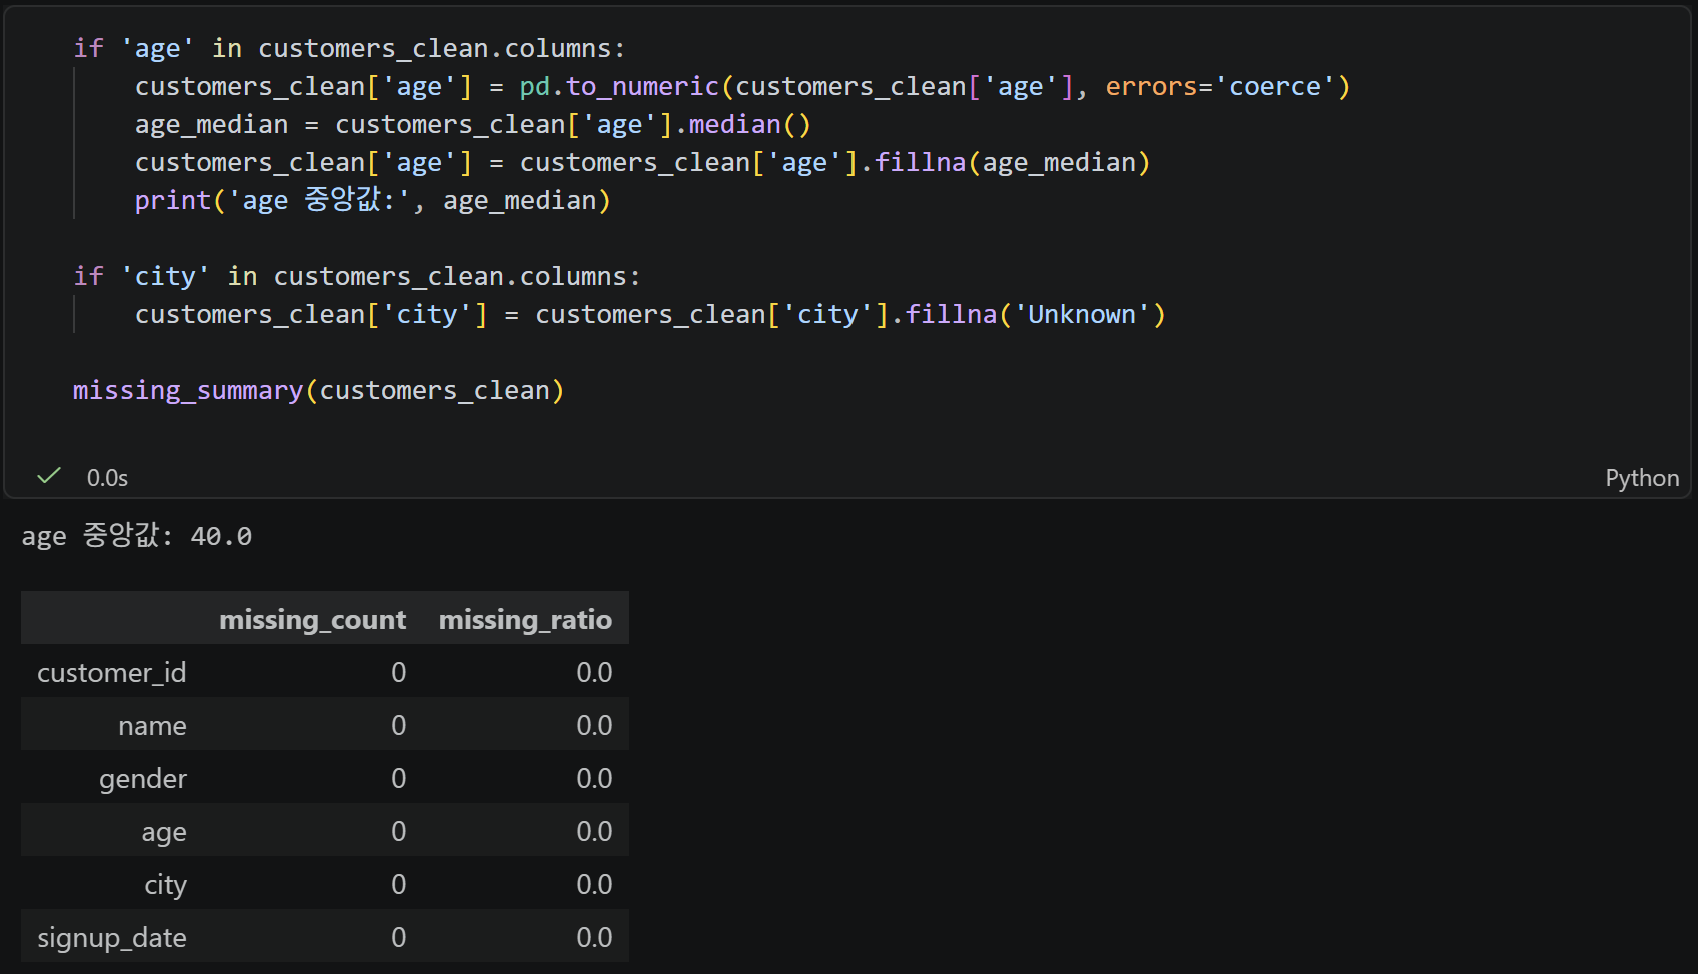
### 결과 관찰
날짜 및 숫자 변환이 성공적으로 이루어졌고, 문자열 정리도 되었다. 공백 제거 후 결측으로 나타나는 행도 없었다.
### 나의 해석과 판단
수치형 변수인 age는 극단적인 값에 영향을 덜 받도록 중앙값으로 대치하였고, 범주형 변수인 city는 unknown으로 따로 표시하여 결측을 정보로 활용하고자 했다. 결측이 있는 행을 제거한다면 단순히 결측이 아닌 행의 데이터를 잃는 것도 있지만, 해당 값이 결측의 원인이 되는 경우 문제가 더 심각하다. 예를 들어 소득을 조사할 때 초고소득자가 소득을 일부러 기입하지 않는 경우 결측이라는 이유로 제거하게 된다면 실제 데이터를 크게 왜곡하는 결과를 낳을 수 있다.
### 업무·분석적 의미
날짜 및 숫자 변환이 성공적으로 이루어졌고, 문자열 정리도 되었다. 결측인 행은 기존 데이터에도 존재하지 않았으나, 결측인 행들이 있었다면 수치형 데이터에서는 중앙값으로, 범주형 데이터에서는 unknown으로 대치되었을 것이다.
### 한계와 추가 확인 사항
결측 처리 및 데이터 타입 변환까지 마무리되었고, 이상치 확인 및 처리를 해야 한다.

In [71]:
print(customers_clean['city'].isna().sum())
print(orders_clean['order_status'].isna().sum())

0
0


## 14. 이상값 후보 확인하기

이상값은 일반적인 범위를 벗어난 값입니다. 하지만 이상값이 항상 오류는 아닙니다. 0원 상품은 이벤트 상품일 수 있고, 음수 수량은 반품을 의미할 수도 있습니다. 먼저 확인하고 기준을 정해야 합니다.


In [72]:
display(products_clean['price'].describe())
display(order_items_clean[['quantity', 'unit_price']].describe())


count       100.000000
mean     110040.000000
std       56433.910574
min        5000.000000
25%       65750.000000
50%      112000.000000
75%      161000.000000
max      200000.000000
Name: price, dtype: float64

,quantity,unit_price
count,764.000000,764.000000
mean,3.053665,108561.518325
std,1.410873,56996.770604
min,1.000000,5000.000000
25%,2.000000,62000.000000
50%,3.000000,111000.000000
75%,4.000000,161250.000000
max,5.000000,200000.000000


In [73]:
print('price <= 0:', len(products_clean[products_clean['price'] <= 0]))
print('quantity <= 0:', len(order_items_clean[order_items_clean['quantity'] <= 0]))
print('unit_price <= 0:', len(order_items_clean[order_items_clean['unit_price'] <= 0]))


price <= 0: 0
quantity <= 0: 0
unit_price <= 0: 0


### 실습용 이상값 처리 기준

이번 실습에서는 정상 주문 분석을 위해 다음 기준을 적용합니다.

```text
- price가 0 이하인 상품은 분석 대상에서 제외
- quantity가 0 이하인 주문 상세는 분석 대상에서 제외
- unit_price가 0 이하인 주문 상세는 분석 대상에서 제외
```

실제 업무에서는 이 기준을 적용하기 전에 반드시 원본 시스템이나 담당자 확인이 필요합니다.


In [74]:
products_clean = products_clean[products_clean['price'] > 0]
order_items_clean = order_items_clean[order_items_clean['quantity'] > 0]
order_items_clean = order_items_clean[order_items_clean['unit_price'] > 0]

print('이상값 처리 후 products:', products_clean.shape)
print('이상값 처리 후 order_items:', order_items_clean.shape)


이상값 처리 후 products: (100, 4)
이상값 처리 후 order_items: (764, 5)


## 3. 중복·범주 표준화·이상값 후보
- 제거/보류한 중복: 네 개 데이터에서 완전히 같은 행의 중복은 모두 0건이었고, 각 테이블의 PK(`customer_id`, `product_id`, `order_id`, `order_item_id`) 중복도 0건이었다. 따라서 실제로 제거된 행은 없었다. 한 주문에 여러 상품이 포함될 수 있으므로 `order_items`의 `order_id` 반복은 중복 오류로 보지 않았다.
- 표준화한 범주값: 문자열 컬럼의 앞뒤 공백을 제거하고, `order_status`의 완료·취소·환불 관련 다양한 표기를 각각 `completed`, `cancelled`, `refunded`로 통일하도록 하였다. 다만 실제 데이터에는 이미 세 범주만 존재하여 빈도는 각각 184건, 64건, 52건으로 유지되었다.
- 허용값 밖 값: `order_status`에서 지정한 세 상태 외의 값은 0건이었고, `price`, `quantity`, `unit_price`에서 0 이하인 값도 모두 0건이었다. 따라서 설정한 규칙으로 제외된 행은 없었다.
- 이상값 후보: 고객 가입일보다 주문일이 앞서는 주문이 **56건(300건 중 18.7%, 고객 31명)** 발견되었다. `price`는 5,000~200,000원, `quantity`는 1~5개, `unit_price`는 5,000~200,000원이며, 해당 수치 범위만으로 오류라고 판단하기는 어렵다. 가입일·주문일의 선후관계가 맞지 않는 56건은 삭제하지 않고 검토 대상으로 남겼다.

![중복 범주 이상값](images/step03_rules.png)

### 결과 관찰
중복 및 가격·수량의 허용 범위에서는 별다른 문제가 발견되지 않았고, 주문 상태도 세 가지 범주로 정리되어 있었다. 하지만 결측치나 중복이 없어도 고객이 가입하기 전에 주문한 것으로 기록된 사례가 56건 확인되었다. 단순히 컬럼별로 값의 범위만 확인했다면 발견하지 못했을 문제로 보인다.

### 나의 해석과 판단
이상값을 자동으로 삭제하는 것은 바람직하지 않다고 생각한다. 예를 들어 0원 상품은 이벤트 상품일 수 있고, 음수 수량은 반품을 기록한 것일 수 있기 때문에 단순히 정상 범위를 벗어났다는 이유만으로 오류라고 볼 수 없다. 이번에 발견된 가입일보다 빠른 주문 역시 날짜 입력 오류일 수도 있지만, 비회원 주문 후 회원가입했거나 기존 고객 정보가 이관되었을 가능성도 있다. 따라서 업무상 가능한 상황인지 확인한 이후에 수정 또는 제외 여부를 판단해야 한다.

### 업무·분석적 의미
상품 및 주문 상세 데이터는 현재 적용된 조건으로 인해 제외된 행이 없어 수량과 금액 집계에 직접적인 변화가 발생하지 않았다. 다만 가입 시점을 기준으로 고객의 최초 구매까지 걸린 시간이나 가입 후 구매 전환율을 분석한다면, 위 56건은 결과를 왜곡할 수 있을 것으로 보인다. 따라서 거래 시점과 회원가입 시점의 관계를 확인하는 작업이 필요하다.

### 한계와 추가 확인 사항
날짜의 선후관계에 문제가 있는 56건에 대해서는 실제 발생 원인을 아직 확인하지 못했다. 또한 현재의 수치형 이상값 기준은 0 이하 여부에 집중하고 있으므로, 상품별 정상 가격 범위, 비정상적인 주문 수량, 프로모션 및 반품 규칙까지 검토할 필요가 있다.


## 15. 파생 컬럼 만들기

전처리된 수량과 단가를 사용하면 주문 상세 금액을 계산할 수 있습니다.

`line_total = quantity × unit_price`


In [75]:
order_items_clean['line_total'] = (
    order_items_clean['quantity'] * order_items_clean['unit_price']
)

order_items_clean[['quantity', 'unit_price', 'line_total']].head()


,quantity,unit_price,line_total
0,3,102000,306000
1,5,25000,125000
2,3,142000,426000
3,3,193000,579000
4,4,189000,756000


In [76]:
print('전처리 후 주문 상세 금액 합계:', order_items_clean['line_total'].sum())


전처리 후 주문 상세 금액 합계: 255610000


In [77]:
order_item_outliers1=order_items[order_items['quantity']<=0]
order_item_outliers2=order_items[order_items['unit_price']<=0]
product_outliers=products[products['price']<=0]
print(len(order_item_outliers1), len(order_item_outliers2), len(product_outliers))

0 0 0


In [78]:
order_outliers=orders[orders['order_status'].isin(['completed', 'cancelled', 'refunded']) == False]
print(len(order_outliers))

0


In [79]:
customer_orders=customers_clean.merge(
    orders_clean, on='customer_id', how='left', validate='one_to_many')
date_problems=customer_orders[customer_orders['signup_date'] > customer_orders['order_date']]
print(len(date_problems))

56


## 16. 파일 간 관계 다시 확인하기

전처리 과정에서 일부 행을 삭제하면 파일 간 관계가 깨질 수 있습니다. 예를 들어 `products`에서 일부 상품을 제외했는데 `order_items`에는 그 상품 ID가 남아 있을 수 있습니다.


In [80]:
invalid_customers = orders_clean[
    ~orders_clean['customer_id'].isin(customers_clean['customer_id'])
]

invalid_orders = order_items_clean[
    ~order_items_clean['order_id'].isin(orders_clean['order_id'])
]

invalid_products = order_items_clean[
    ~order_items_clean['product_id'].isin(products_clean['product_id'])
]

relationship_checks = pd.DataFrame({
    'check': [
        'orders.customer_id exists in customers.customer_id',
        'order_items.order_id exists in orders.order_id',
        'order_items.product_id exists in products.product_id',
    ],
    'invalid_count': [
        len(invalid_customers),
        len(invalid_orders),
        len(invalid_products),
    ],
})

relationship_checks


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


## 4. PK/FK와 파생 컬럼 재검증
- 없는 `customer_id`: 0건. `orders.customer_id`는 모두 `customers.customer_id`에 존재한다.
- 없는 `order_id`: 0건. `order_items.order_id`는 모두 `orders.order_id`에 존재한다.
- 없는 `product_id`: 0건. `order_items.product_id`는 모두 `products.product_id`에 존재한다.
- 생성한 파생 컬럼: 주문일에서 `order_month`와 `order_dayofweek`를 만들었고, 주문 상세에서 `line_total = quantity × unit_price`를 생성하였다.
- `line_total` 검증: 764개 주문 상세 행의 수량과 단가를 곱한 값과 일치하였고, 전체 합계는 **255,610,000원**이었다. 추가로 764개 행의 `unit_price`가 연결된 상품의 `price`와 모두 일치하는 것도 확인하였다. 다만 취소·환불 주문이 포함된 합계이므로 실제 매출액으로 해석할 수는 없다.

![관계와 파생 컬럼 검증](images/step04_validation.png)
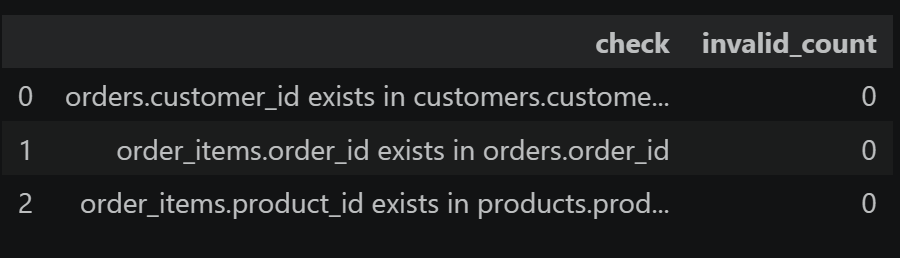

### 결과 관찰
전처리 이후에도 세 가지 FK 관계에서 참조할 수 없는 ID는 발견되지 않았다. 파생 컬럼을 생성하면서 `orders`에는 월과 요일 컬럼이 추가되어 5개에서 7개로, `order_items`에는 금액 컬럼이 추가되어 5개에서 6개로 열 수가 늘어났다. 기존 행 수와 PK의 유일성은 그대로 유지되었다.

### 나의 해석과 판단
한 테이블에서 문제가 있는 행을 삭제하면 다른 테이블에서는 해당 행을 계속 참조할 수 있으므로, 전처리 이전에 PK/FK 관계가 정상이었다고 해서 이후에도 정상이라고 단정할 수 없다. 예를 들어 가격 문제로 상품을 제거한다면 주문 상세에 남아 있는 `product_id`가 더 이상 상품 테이블과 연결되지 않을 수 있다. 이번에는 제외된 행이 없어 관계가 유지되었지만, 전처리 규칙이 바뀌더라도 같은 검증을 다시 수행해야 한다. 또한 PK/FK가 정상인 것과 날짜 등 업무 규칙까지 정상인 것은 서로 다른 문제라고 판단된다.


## 17. 전처리 전후 비교하기

전처리 전후 데이터 크기를 비교합니다. 행 수가 줄었다면 어떤 기준으로 줄었는지 설명할 수 있어야 하고, 열 수가 늘었다면 어떤 파생 컬럼이 추가되었는지 설명할 수 있어야 합니다.


In [81]:
processed_data = {
    'customers': customers_clean,
    'products': products_clean,
    'orders': orders_clean,
    'order_items': order_items_clean,
}

processed_shapes = pd.DataFrame({
    'dataset': list(processed_data.keys()),
    'rows': [df.shape[0] for df in processed_data.values()],
    'columns': [df.shape[1] for df in processed_data.values()],
})

comparison = raw_shapes.merge(
    processed_shapes,
    on='dataset',
    suffixes=('_raw', '_processed')
)

comparison


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,products,100,4,100,4
2,orders,300,5,300,7
3,order_items,764,5,764,6


## 18. 전처리 결과 저장하기

전처리된 데이터는 `data/processed` 폴더에 저장합니다. Excel에서 한글 CSV를 바로 열 수 있도록 `utf-8-sig` 인코딩을 사용합니다.


In [82]:
customers_clean.to_csv(PROCESSED_DIR / 'customers_clean.csv', index=False, encoding='utf-8-sig')
products_clean.to_csv(PROCESSED_DIR / 'products_clean.csv', index=False, encoding='utf-8-sig')
orders_clean.to_csv(PROCESSED_DIR / 'orders_clean.csv', index=False, encoding='utf-8-sig')
order_items_clean.to_csv(PROCESSED_DIR / 'order_items_clean.csv', index=False, encoding='utf-8-sig')

list(PROCESSED_DIR.glob('*_clean.csv'))


[WindowsPath('c:/Users/rhrnf/llm-data-analysis-study/data/processed/customers_clean.csv'),
 WindowsPath('c:/Users/rhrnf/llm-data-analysis-study/data/processed/orders_clean.csv'),
 WindowsPath('c:/Users/rhrnf/llm-data-analysis-study/data/processed/order_items_clean.csv'),
 WindowsPath('c:/Users/rhrnf/llm-data-analysis-study/data/processed/products_clean.csv')]

## 5. 전처리 전/후 비교
| 항목 | 처리 전 | 처리 후 | 변화 이유 |
| --- | ---: | ---: | --- |
| 행 수(4개 파일 합계) | 1,314 | 1,314 | 완전 중복 및 0 이하 가격·수량·단가에 해당하는 행이 없어 삭제된 행이 없었다. |
| 결측(전체 셀 기준) | 0건 | 0건 | 원본부터 결측이 없었고 타입 변환에서도 새로운 결측이 발생하지 않았다. |
| 완전 중복(4개 파일 합계) | 0건 | 0건 | 중복 제거 코드를 실행했으나 제거 대상이 없었다. |
| 변환 실패(날짜·숫자) | 미측정(변환 전) | 0건 | 날짜 컬럼 2개와 숫자 컬럼 3개를 변환했고 실패한 값은 없었다. |
| 열 수(4개 파일 합계) | 20 | 23 | `order_month`, `order_dayofweek`, `line_total` 파생 컬럼 3개를 추가하였다. |

개별 데이터의 변화는 `customers` **(150, 6) → (150, 6)**, `products` **(100, 4) → (100, 4)**, `orders` **(300, 5) → (300, 7)**, `order_items` **(764, 5) → (764, 6)**이다. 위 합계는 서로 다른 테이블의 행 수를 단순히 더한 것으로, 주문 수 또는 고객 수를 의미하지 않는다.

![전처리 전후 비교](images/step05_before_after.png)
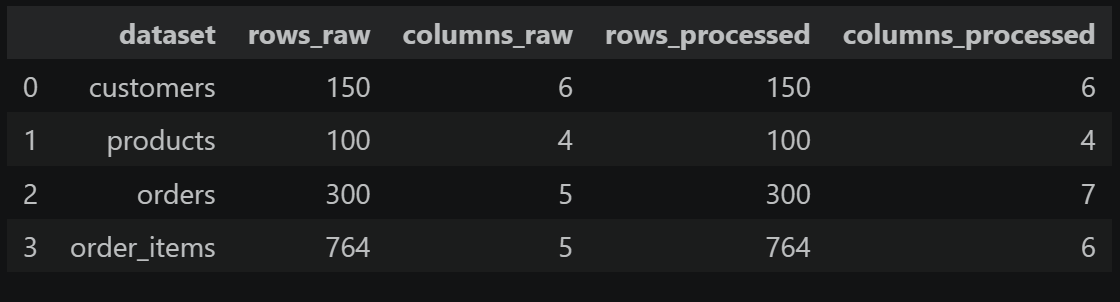

### 결과 관찰
네 개 데이터의 행 수는 모두 유지되었고, 결측 및 완전 중복 건수에도 변화가 없었다. 날짜와 숫자형으로의 변환은 모두 성공하였으며, 분석에 활용할 수 있는 월·요일·금액 파생 컬럼 3개가 추가되었다. 주문 상태값의 분포 역시 `completed` 184건, `cancelled` 64건, `refunded` 52건으로 유지되었다.

### 나의 해석과 판단
이번 전처리에서 행 수가 줄지 않은 것은 중복 제거 또는 이상값 제외 코드가 작동하지 않았기 때문이 아니라, 실제로 해당 규칙에 걸리는 데이터가 없었기 때문이다. 결과적으로 행의 수나 기존 값의 분포가 크게 변하지 않은 것은 의도한 결과로 볼 수 있다. 다만 값이 변하지 않았다는 사실만으로 데이터의 품질이 충분하다고 결론 내릴 수는 없다. 앞서 확인한 가입일보다 빠른 주문 56건은 여전히 남아 있기 때문이다.

### 업무·분석적 의미
기존 고객·상품·주문 기록의 행 수를 유지하면서 날짜 및 금액 집계에 필요한 컬럼을 추가하였으므로 후속 EDA를 수행하기가 쉬워졌다. 다만 `line_total`의 전체 합계에는 취소 및 환불 주문도 포함되어 있으므로 매출 분석에서는 주문 상태별로 구분할 필요가 있다.

### 한계와 추가 확인 사항
지금까지의 전처리는 컬럼별 형식과 기본적인 유효성 검증에 집중하고 있다. 실제 주문 처리 절차에 따른 날짜 순서, 취소·환불 금액 반영 방식, 상품 가격의 시점별 변경 여부 등을 추가로 검증해야 한다. 특히 고객 가입일보다 빠른 주문 56건의 처리 기준에 따라 가입 후 구매 전환 관련 분석 결과가 달라질 수 있다.


## 19. 전처리 요약 보고서 저장하기

전처리 기준과 결과를 Markdown 파일로 남겨 두면 이후 보고서 작성이 쉬워집니다.


In [83]:
summary_text = f'''# Chapter 5 데이터 전처리 요약

## 전처리 결과 파일

- customers_clean.csv
- products_clean.csv
- orders_clean.csv
- order_items_clean.csv

## 전처리 전후 데이터 크기

```text
{comparison.to_string(index=False)}
```

## 파일 간 관계 점검 결과

```text
{relationship_checks.to_string(index=False)}
```

## 주요 처리 내용

- 원본 데이터를 직접 수정하지 않고 복사본을 사용함
- 문자열 컬럼 앞뒤 공백 제거
- 고객 나이 결측치는 중앙값으로 대체
- 고객 도시 결측치는 Unknown으로 처리
- 주문 상태값 표기 통일
- 날짜 컬럼 변환 및 주문 월/요일 파생 컬럼 생성
- 가격, 수량, 단가를 숫자형으로 변환
- 0 이하 가격, 수량, 단가 확인 및 처리
- line_total 파생 컬럼 생성
- 파일 간 키 관계 재확인

## 주의 사항

이 전처리 기준은 실습용 예시입니다. 실제 업무에서는 결측치와 이상값을 삭제하거나 대체하기 전에 원본 시스템, 수집 과정, 업무 담당자 확인이 필요합니다.
'''

report_path = REPORT_DIR / 'ch05_preprocessing_summary.md'
report_path.write_text(summary_text, encoding='utf-8')

print('요약 보고서 저장 완료:', report_path)


요약 보고서 저장 완료: c:\Users\rhrnf\llm-data-analysis-study\reports\ch05_preprocessing_summary.md


## 20. 전처리 과정을 함수로 정리하기

전처리 코드를 한 번만 실행하고 끝내면 재사용하기 어렵습니다. 같은 데이터를 다시 받거나 처리 기준을 조금 바꾸어야 할 때는 함수로 정리된 코드가 훨씬 유용합니다.


In [84]:
def preprocess_customers(df):
    result = strip_string_columns(df)

    if 'age' in result.columns:
        result['age'] = pd.to_numeric(result['age'], errors='coerce')
        result['age'] = result['age'].fillna(result['age'].median())

    if 'city' in result.columns:
        result['city'] = result['city'].fillna('Unknown')

    if 'signup_date' in result.columns:
        result['signup_date'] = pd.to_datetime(result['signup_date'], errors='coerce')

    return result.drop_duplicates()


def preprocess_products(df):
    result = strip_string_columns(df)

    if 'price' in result.columns:
        result['price'] = to_number(result['price'])
        result = result[result['price'] > 0]

    return result.drop_duplicates()


def preprocess_orders(df):
    result = strip_string_columns(df)

    if 'order_status' in result.columns:
        result['order_status'] = result['order_status'].replace(status_map)

    if 'order_date' in result.columns:
        result['order_date'] = pd.to_datetime(result['order_date'], errors='coerce')
        result['order_month'] = result['order_date'].dt.to_period('M').astype(str)
        result['order_dayofweek'] = result['order_date'].dt.day_name()

    return result.drop_duplicates()


def preprocess_order_items(df):
    result = strip_string_columns(df)

    if 'quantity' in result.columns:
        result['quantity'] = to_number(result['quantity'])
        result = result[result['quantity'] > 0]

    if 'unit_price' in result.columns:
        result['unit_price'] = to_number(result['unit_price'])
        result = result[result['unit_price'] > 0]

    if {'quantity', 'unit_price'}.issubset(result.columns):
        result['line_total'] = result['quantity'] * result['unit_price']

    return result.drop_duplicates()


In [85]:
customers_clean_func = preprocess_customers(customers)
products_clean_func = preprocess_products(products)
orders_clean_func = preprocess_orders(orders)
order_items_clean_func = preprocess_order_items(order_items)

print(customers_clean_func.shape)
print(products_clean_func.shape)
print(orders_clean_func.shape)
print(order_items_clean_func.shape)


(150, 6)
(100, 4)
(300, 7)
(764, 6)


C:\Users\rhrnf\AppData\Local\Temp\ipykernel_35928\1976643875.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_columns = result.select_dtypes(include='object').columns
C:\Users\rhrnf\AppData\Local\Temp\ipykernel_35928\1976643875.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/us

## 21. 소스 모듈 사용하기

위에서 직접 작성한 전처리 함수는 `src/preprocessing.py`에도 정리되어 있습니다. 반복 작업이나 실제 프로젝트에서는 노트북 안에만 코드를 두기보다 소스 모듈로 분리하는 것이 좋습니다.


In [34]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    build_preprocessing_report,
    compare_shapes,
    duplicate_summary,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)

module_raw_data = load_sales_data(RAW_DIR)
module_processed_data = preprocess_sales_data(module_raw_data)
module_relationship_checks = validate_relationships(module_processed_data)
module_comparison = compare_shapes(module_raw_data, module_processed_data)

module_comparison


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,products,100,4,100,4
2,orders,300,5,300,7
3,order_items,764,5,764,6


In [35]:
duplicate_summary(
    module_processed_data,
    key_columns={
        'customers': 'customer_id',
        'products': 'product_id',
        'orders': 'order_id',
        'order_items': 'order_item_id',
    },
)


,dataset,duplicate_rows,duplicate_keys
0,customers,0,0
1,products,0,0
2,orders,0,0
3,order_items,0,0


In [36]:
module_relationship_checks


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


## 22. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 전처리 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/preprocess_data.py
```

이 스크립트는 전처리 결과 CSV와 요약 보고서를 자동으로 저장합니다.


## 6. 재현 가능한 전처리 확인
- 생성된 clean CSV: `data/processed/customers_clean.csv`, `data/processed/products_clean.csv`, `data/processed/orders_clean.csv`, `data/processed/order_items_clean.csv`의 4개 파일을 생성하였다.
- 생성된 요약 보고서: `reports/ch05_preprocessing_summary.md`를 생성하였고, 전처리 전후 크기와 관계 검증 결과, 주요 처리 사항을 기록하였다.
- `python scripts/preprocess_data.py` 재실행 결과: 함께 제공한 실행 보조 스크립트로 재실행하여 4개 파일의 행 수 150, 100, 300, 764건과 열 수 6, 4, 7, 6개가 유지되는 것을 확인하였다. 세 가지 FK 관계의 오류도 모두 0건이었다. 이 스크립트는 별도 첨부되지 않은 원본 프로젝트 스크립트를 대신하여 현재 Notebook의 전처리 규칙을 기준으로 구성한 것이다.
- 재실행 후 달라진 점: 동일한 원본과 처리 기준으로 두 번 실행했을 때 4개 clean CSV와 요약 보고서의 내용이 달라지지 않았다. 기존 결과를 덮어쓰더라도 같은 결과가 만들어지는 것을 확인하였다.

![재실행 결과](images/step06_reproducible.png)

### 나의 해석과 판단
Notebook에서 한 번 성공하는 것만으로는 전처리가 재현 가능하다고 단정할 수 없다. 이전 셀에서 만들어진 변수나 코드 실행 순서에 의존할 수도 있고, 다른 환경에서는 파일 경로나 외부 모듈이 없어 실행되지 않을 수도 있기 때문이다. 반면 스크립트로 실행했을 때 동일한 원본으로부터 같은 결과가 생성된다면 처리 과정의 일관성을 확인할 수 있다. 다만 단순히 다시 실행되는 것만으로 전처리 기준이 옳다고 증명되는 것은 아니므로, 데이터가 변경될 때 검증 결과도 함께 확인해야 한다.


## 23. LLM과 함께 전처리 코드를 검토하기

LLM에게 전처리 코드를 요청할 때는 실제 고객명, 이메일, 주문 내역을 그대로 입력하지 않는 것이 좋습니다. 컬럼명, 데이터 타입, 결측치 개수, 중복 여부, 처리 목적처럼 구조화된 정보만 제공하세요.

```text
다음 전처리 코드가 안전한지 검토해 주세요.

customers["age"] = customers["age"].fillna(customers["age"].mean())
customers = customers.drop_duplicates()
orders["order_date"] = pd.to_datetime(orders["order_date"])
order_items["line_total"] = order_items["quantity"] * order_items["unit_price"]

검토 기준:
- 원본 데이터를 직접 수정하는 문제가 있는지
- 결측치 처리 방식이 적절한지
- 날짜 변환 실패를 확인하는지
- 중복 제거 기준이 충분한지
- line_total 계산 전에 숫자형 변환이 필요한지
- 더 안전한 코드로 어떻게 수정할 수 있는지
```


## 7. Chapter 05 최종 판단
### 내가 정한 전처리 원칙 3가지
1. 원본 데이터를 덮어쓰지 않고 복사본에서 처리하며, 처리 전후 행 수와 데이터 상태를 함께 기록해야 한다.
2. 결측치와 이상값은 무조건 삭제하거나 대체하기보다 해당 값이 발생한 이유와 컬럼의 업무적 의미를 먼저 확인해야 한다.
3. 전처리 이후에는 개별 컬럼뿐 아니라 PK/FK 관계와 컬럼 간 업무 규칙을 재검증하고, 같은 과정을 다시 실행할 수 있도록 처리 기준을 남겨야 한다.

### 가장 위험하다고 생각한 자동 처리 1가지와 이유
이상값을 발견하자마자 해당 행을 자동 삭제하는 것이 가장 위험하다고 생각한다. 특히 이번 데이터에서 발견된 가입일보다 빠른 주문 56건은 언뜻 보면 날짜 오류처럼 보이지만, 비회원 구매나 고객 정보 이관 등 다른 이유로 발생했을 가능성도 있다. 이 행들을 일괄 삭제한다면 실제 거래 내역이 분석에서 빠지고, 고객별 구매 건수나 매출 관련 분석이 왜곡될 수 있다. 따라서 원인을 확인하기 전에는 별도 표시하여 검토하는 편이 적절하다고 판단된다.

### 다음 EDA에서 특히 주의할 데이터 특성
주문 상태는 `completed` 184건, `cancelled` 64건, `refunded` 52건으로 구분된다. `line_total` 전체 합계 255,610,000원에는 취소·환불 주문도 포함되므로, 이를 실제 매출액으로 해석하지 않도록 주의해야 한다. 또한 가입일보다 주문일이 앞서는 56건을 포함한 채 가입 후 첫 구매까지의 기간이나 전환율을 구하면 비정상적인 결과가 나올 수 있다. 고객·주문·주문 상세를 결합할 때는 한 주문에 여러 상세 행이 존재하므로 단순 행 개수를 주문 건수로 해석하지 않아야 한다.

### 현재 전처리의 한계
결측치·중복·기본적인 타입 및 숫자 범위·FK 관계는 확인하였으나, 실제 업무 규칙의 타당성까지 검증한 것은 아니다. 가입일과 주문일의 불일치 원인을 확인하지 못했고, 상품 가격의 변경 이력이나 취소·환불 처리 기준도 확인되지 않았다. 현재 사용하는 0 이하 값 제외 기준은 실습용이므로, 실제 분석에서는 업무 담당자나 원천 시스템을 통해 해당 기준이 적절한지 확인해야 한다.

## 최종 제출 체크
- [V] raw 원본을 덮어쓰지 않았습니다.
- [V] 처리 전/후 비교를 남겼습니다.
- [V] 처리 기준과 이유를 자신의 말로 작성했습니다.
- [V] clean CSV와 재실행 결과를 확인했습니다.
- [V] 개인정보/Secret이 없습니다. (제출 전에 첨부 데이터와 Notebook을 직접 확인할 예정입니다.)
- [V] `chapter05/chapter05.ipynb`가 GitHub에서 정상 표시됩니다.
- [V] 최종 Notebook 파일 URL을 제출합니다.


## 24. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 각 데이터셋의 결측치 비율을 하나의 표로 합쳐 보세요.
2. `customers_clean`에서 나이가 18세 미만이거나 100세 초과인 값이 있는지 확인하세요.
3. `orders_clean`에서 월별 주문 건수를 계산하세요.
4. `order_items_clean`에서 `line_total`이 큰 순서대로 상위 10개를 확인하세요.
5. 전처리 전후 행 수가 줄어든 데이터셋이 있는지 설명해 보세요.
6. LLM에게 결측치 처리 기준을 검토해 달라는 프롬프트를 직접 작성해 보세요.


In [88]:
# 과제 1. 각 데이터셋의 결측치 비율을 하나의 표로 합쳐 보세요.
# hint: missing_summary(df).reset_index()를 활용해 보세요.
for name, df in processed_data.items():
    print(missing_summary(df).reset_index().rename(columns={'index': 'column'}))

        column  missing_count  missing_ratio
0  customer_id              0            0.0
1         name              0            0.0
2       gender              0            0.0
3          age              0            0.0
4         city              0            0.0
5  signup_date              0            0.0
         column  missing_count  missing_ratio
0    product_id              0            0.0
1  product_name              0            0.0
2      category              0            0.0
3         price              0            0.0
            column  missing_count  missing_ratio
0         order_id              0            0.0
1      customer_id              0            0.0
2       order_date              0            0.0
3   payment_method              0            0.0
4     order_status              0            0.0
5      order_month              0            0.0
6  order_dayofweek              0            0.0
          column  missing_count  missing_ratio
0  order_item_id

In [91]:
# 과제 2. customers_clean에서 나이가 18세 미만이거나 100세 초과인 값이 있는지 확인하세요.
print(customers_clean[(customers_clean['age'] < 18) | (customers_clean['age'] > 100)])

Empty DataFrame
Columns: [customer_id, name, gender, age, city, signup_date]
Index: []


In [92]:
# 과제 3. orders_clean에서 월별 주문 건수를 계산하세요.
order_counts_by_month = orders_clean.groupby('order_month').size().reset_index(name='order_count')
print(order_counts_by_month)

   order_month  order_count
0      2025-09           11
1      2025-10           28
2      2025-11           20
3      2025-12           36
4      2026-01           27
5      2026-02           20
6      2026-03           31
7      2026-04           33
8      2026-05           21
9      2026-06           28
10     2026-07           25
11     2026-08           14
12     2026-09            6


In [93]:
# 과제 4. order_items_clean에서 line_total이 큰 순서대로 상위 10개를 확인하세요.
order_items_top10 = order_items_clean.nlargest(10, 'line_total')

## 25. 정리

이번 장에서는 다음 내용을 실습했습니다.

- 원본 데이터와 전처리 데이터 분리
- 결측치 개수와 비율 확인
- 나이 결측치 중앙값 대체, 도시 결측치 Unknown 처리
- 중복 행과 주요 ID 중복 점검
- 문자열 앞뒤 공백 제거와 상태값 표기 통일
- 날짜형 변환과 주문 월/요일 파생 컬럼 생성
- 숫자형 변환과 변환 실패 건수 확인
- 이상값 후보 확인과 실습용 처리 기준 적용
- 주문 상세 금액 `line_total` 생성
- 파일 간 키 관계 재확인
- 전처리 결과 CSV와 요약 보고서 저장
- 전처리 함수를 `src/preprocessing.py` 소스 모듈로 분리

다음 장에서는 전처리된 데이터를 바탕으로 탐색적 데이터 분석, 즉 EDA를 수행합니다.
